In [10]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

pd.set_option("display.width", 140)
df = pd.read_csv("dataset.csv", parse_dates=["timestamp"])
print(df.shape, "| nulls:", int(df.isna().sum().sum()))
df.head()

(500, 7) | nulls: 0


,user_id,movie_title,genre,language,release_year,rating,timestamp
0,496,Pink,Thriller,Tamil,2010,3.5,2025-09-06
1,42,KGF,Action,Tamil,2020,4.0,2024-05-03
2,80,Pink,Action,Hindi,2010,5.0,2025-06-11
3,390,RRR,Comedy,Kannada,2015,3.0,2024-05-18
4,156,Baahubali,Thriller,Tamil,2012,4.0,2024-11-09


## 1. Data understanding and cleaning

In [11]:
print("users:", df.user_id.nunique(), "| movies:", df.movie_title.nunique())
print("repeat (user, movie) pairs:", int(df.duplicated(["user_id", "movie_title"]).sum()))
per_user = df.groupby("user_id").size()
print("ratings per user: median", per_user.median(), "| users with 1 rating:", int((per_user == 1).sum()))
# genre / language / release_year differ from row to row for the same movie
print(df.groupby("movie_title")[["genre", "language", "release_year"]].nunique())

users: 309 | movies: 8
repeat (user, movie) pairs: 27
ratings per user: median 1.0 | users with 1 rating: 178
             genre  language  release_year
movie_title                               
3 Idiots         6         4            15
Andhadhun        6         4            15
Baahubali        6         4            15
Dangal           6         4            15
Drishyam         6         4            15
KGF              6         4            15
Pink             6         4            15
RRR              6         4            15


**Findings that shape the design**
- Very sparse: most users rated one movie, so user-user similarity has little to work with.
- Only 8 movies, so "recommend" means ranking the unseen ones out of at most 7.
- `genre`, `language`, `release_year` are not stable per movie (each film appears under all 6 genres),
  so they describe the *viewing record*, not the film. The content model therefore learns
  what each user liked in those attributes rather than trusting a fixed movie genre.
- Repeat (user, movie) pairs are collapsed to the latest rating.

after de-duplication: (473, 7)


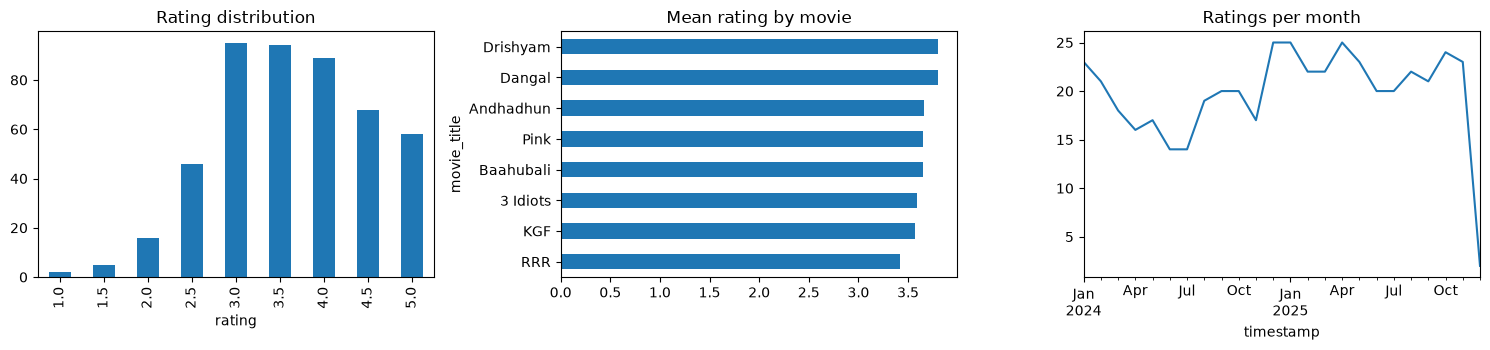

In [12]:
clean = (df.sort_values("timestamp")
           .drop_duplicates(["user_id", "movie_title"], keep="last")
           .reset_index(drop=True))
print("after de-duplication:", clean.shape)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
clean.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Rating distribution")
clean.groupby("movie_title").rating.mean().sort_values().plot.barh(ax=ax[1], title="Mean rating by movie")
clean.groupby(clean.timestamp.dt.to_period("M")).size().plot(ax=ax[2], title="Ratings per month")
plt.tight_layout(); plt.show()

## 2. Evaluation setup (leave-one-out)
For every user with 2+ ratings, hold out their most recent rating and train on the rest.
Metrics: RMSE/MAE on the held-out rating, and Hit-Rate@3 / MRR for ranking
(is the held-out movie, which the user liked, ranked high among movies not yet seen?).
A "liked" holdout means rating >= 4.

In [13]:
clean = clean.sort_values(["user_id", "timestamp"])
test_idx = clean.groupby("user_id").tail(1).index[clean.groupby("user_id").size().reindex(
    clean.groupby("user_id").tail(1).user_id).values >= 2]
test, train = clean.loc[test_idx], clean.drop(test_idx)
print("train:", len(train), "| test:", len(test), "| liked test items:", int((test.rating >= 4).sum()))

movies = sorted(clean.movie_title.unique())
users = sorted(clean.user_id.unique())
m_idx = {m: i for i, m in enumerate(movies)}
u_idx = {u: i for i, u in enumerate(users)}

def to_matrix(d):
    R = np.zeros((len(users), len(movies)))
    for u, m, r in zip(d.user_id, d.movie_title, d.rating):
        R[u_idx[u], m_idx[m]] = r
    return R

R = to_matrix(train)
mask = R > 0
gmean = R[mask].mean()
item_mean = np.array([R[mask[:, j], j].mean() if mask[:, j].any() else gmean for j in range(len(movies))])
user_mean = np.array([R[i, mask[i]].mean() if mask[i].any() else gmean for i in range(len(users))])
print("global mean:", round(gmean, 3))

train: 354 | test: 119 | liked test items: 46
global mean: 3.669


## 3. Models
Each model returns a score matrix `S[user, movie]` on the 1-5 scale.

In [14]:
# 3.1 Popularity: Bayesian-shrunk movie mean (also the cold-start fallback)
cnt = mask.sum(0); k = 10
pop = (cnt * item_mean + k * gmean) / (cnt + k)
S_pop = np.tile(pop, (len(users), 1))

# 3.2 Item-based CF: similarity between mean-centred movie columns
Rc = np.where(mask, R - user_mean[:, None], 0)
item_sim = cosine_similarity(Rc.T); np.fill_diagonal(item_sim, 0)
def item_cf(shrink=5):
    S = np.zeros_like(R)
    for i in range(len(users)):
        rated = mask[i]
        for j in range(len(movies)):
            w = item_sim[j, rated]
            num = (w * Rc[i, rated]).sum(); den = np.abs(w).sum() + shrink
            S[i, j] = pop[j] + num / den if rated.any() else pop[j]
    return np.clip(S, 1, 5)
S_item = item_cf()

# 3.3 User-based CF
user_sim = cosine_similarity(Rc); np.fill_diagonal(user_sim, 0)
def user_cf(shrink=5):
    S = np.tile(pop, (len(users), 1)).astype(float)
    for i in range(len(users)):
        for j in range(len(movies)):
            raters = mask[:, j]
            w = user_sim[i, raters]
            S[i, j] = pop[j] + (w * Rc[raters, j]).sum() / (np.abs(w).sum() + shrink)
    return np.clip(S, 1, 5)
S_user = user_cf()

# 3.4 Matrix factorization (SVD on residuals from the popularity baseline)
resid = np.where(mask, R - pop[None, :], 0)
svd = TruncatedSVD(n_components=3, random_state=42).fit(resid)
S_svd = np.clip(pop[None, :] + 0.5 * svd.inverse_transform(svd.transform(resid)), 1, 5)

# 3.5 Content-based: learn each user's taste over genre / language / decade from ratings,
#     then score a movie by how well its historical attribute mix matches that taste.
feat = train.assign(decade=(train.release_year // 5) * 5)
cols = ["genre", "language", "decade"]
X = pd.concat([pd.get_dummies(feat[c], prefix=c) for c in cols], axis=1).astype(float)
movie_profile = X.groupby(feat.movie_title.values).mean().reindex(movies)      # movie x attrs
user_profile = (X.mul(feat.rating.values - gmean, axis=0)
                  .groupby(feat.user_id.values).mean().reindex(users).fillna(0))  # user x attrs
S_content = np.clip(pop[None, :] + 1.0 * (user_profile.values @ movie_profile.values.T), 1, 5)

# 3.6 Hybrid: weighted blend
# Content model is left out of the blend: in section 4 it scores worse than the baseline
# (the genre/language columns are not stable per movie, so it overfits).
S_hyb = (S_item + S_user + S_svd) / 3
scores = {"Popularity": S_pop, "Item CF": S_item, "User CF": S_user, "SVD": S_svd,
          "Content": S_content, "Hybrid": S_hyb}

## 4. Evaluation

In [15]:
def evaluate(S):
    err, hits, rr = [], [], []
    for u, m, r in zip(test.user_id, test.movie_title, test.rating):
        i, j = u_idx[u], m_idx[m]
        err.append(S[i, j] - r)
        if r >= 4:
            cand = [c for c in range(len(movies)) if not mask[i, c]]      # unseen in train
            order = sorted(cand, key=lambda c: -S[i, c])
            rank = order.index(j) + 1
            hits.append(rank <= 3); rr.append(1 / rank)
    err = np.array(err)
    return {"RMSE": np.sqrt((err ** 2).mean()), "MAE": np.abs(err).mean(),
            "HitRate@3": np.mean(hits), "MRR": np.mean(rr)}

rng = np.random.default_rng(0)
S_rand = rng.uniform(1, 5, S_pop.shape)
res = pd.DataFrame({k: evaluate(v) for k, v in {**scores, "Random": S_rand}.items()}).T.round(3)
res.loc["Global mean (rating only)", ["RMSE", "MAE"]] = [
    np.sqrt(((gmean - test.rating) ** 2).mean()).round(3), (gmean - test.rating).abs().mean().round(3)]
print(res)
res

                            RMSE    MAE  HitRate@3    MRR
Popularity                 0.854  0.702      0.435  0.404
Item CF                    0.851  0.701      0.435  0.400
User CF                    0.851  0.700      0.500  0.420
SVD                        0.853  0.710      0.457  0.413
Content                    1.128  0.893      0.370  0.421
Hybrid                     0.851  0.703      0.522  0.415
Random                     1.510  1.231      0.457  0.393
Global mean (rating only)  0.855  0.711        NaN    NaN


,RMSE,MAE,HitRate@3,MRR
Popularity,0.854,0.702,0.435,0.404
Item CF,0.851,0.701,0.435,0.400
User CF,0.851,0.700,0.500,0.420
SVD,0.853,0.710,0.457,0.413
Content,1.128,0.893,0.370,0.421
Hybrid,0.851,0.703,0.522,0.415
Random,1.510,1.231,0.457,0.393
Global mean (rating only),0.855,0.711,NaN,NaN


## 5. Recommender function

In [16]:
def recommend(user_id, n=3, model="Hybrid", show_reasons=True):
    S = scores[model]
    if user_id not in u_idx or not mask[u_idx[user_id]].any():
        print(f"User {user_id}: no history, showing the most popular movies (cold start).")
        order = np.argsort(-pop)[:n]
        return pd.DataFrame({"movie": [movies[j] for j in order], "predicted_rating": pop[order].round(2)})
    i = u_idx[user_id]
    seen = [movies[j] for j in np.where(mask[i])[0]]
    order = [j for j in np.argsort(-S[i]) if not mask[i, j]][:n]
    out = pd.DataFrame({"movie": [movies[j] for j in order], "predicted_rating": S[i, order].round(2)})
    if show_reasons:
        liked = clean[(clean.user_id == user_id) & (clean.rating >= 4)].movie_title.tolist()
        out["why"] = [f"Blend of popularity and taste similarity; you rated {', '.join(liked)} highly" if liked
                      else "Strong overall rating among all viewers" for _ in order]
    print(f"User {user_id} has rated: {seen}")
    return out

multi = per_user[per_user >= 3].index[:2].tolist()
for u in multi + [999999]:
    print(recommend(u).to_string(), "\n")

User 31 has rated: ['3 Idiots', 'KGF', 'Pink']
       movie  predicted_rating                                                             why
0   Drishyam              3.89  Blend of popularity and taste similarity; you rated KGF highly
1     Dangal              3.85  Blend of popularity and taste similarity; you rated KGF highly
2  Andhadhun              3.64  Blend of popularity and taste similarity; you rated KGF highly 

User 37 has rated: ['3 Idiots', 'Baahubali', 'KGF']
       movie  predicted_rating                                                                        why
0   Drishyam              3.81  Blend of popularity and taste similarity; you rated Baahubali, KGF highly
1     Dangal              3.81  Blend of popularity and taste similarity; you rated Baahubali, KGF highly
2  Andhadhun              3.68  Blend of popularity and taste similarity; you rated Baahubali, KGF highly 

User 999999: no history, showing the most popular movies (cold start).
      movie  predicted

In [18]:
# %% [markdown]
# # Personalized Movie Recommendation System
# Dataset: 500 ratings, 8 Indian films, 309 users (`dataset.csv`).
# Approaches: popularity baseline, item-based CF, user-based CF, matrix factorization (SVD),
# content-based, and a hybrid. All are compared on a leave-one-out holdout.

# %%
from pathlib import Path
import matplotlib
matplotlib.use("Agg")  # save charts to a file instead of opening blocking windows
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD

pd.set_option("display.width", 140)
df = pd.read_csv(Path(__file__).resolve().parent / "dataset.csv", parse_dates=["timestamp"])
print(df.shape, "| nulls:", int(df.isna().sum().sum()))
df.head()

# %% [markdown]
# ## 1. Data understanding and cleaning

# %%
print("users:", df.user_id.nunique(), "| movies:", df.movie_title.nunique())
print("repeat (user, movie) pairs:", int(df.duplicated(["user_id", "movie_title"]).sum()))
per_user = df.groupby("user_id").size()
print("ratings per user: median", per_user.median(), "| users with 1 rating:", int((per_user == 1).sum()))
# genre / language / release_year differ from row to row for the same movie
print(df.groupby("movie_title")[["genre", "language", "release_year"]].nunique())

# %% [markdown]
# **Findings that shape the design**
# - Very sparse: most users rated one movie, so user-user similarity has little to work with.
# - Only 8 movies, so "recommend" means ranking the unseen ones out of at most 7.
# - `genre`, `language`, `release_year` are not stable per movie (each film appears under all 6 genres),
#   so they describe the *viewing record*, not the film. The content model therefore learns
#   what each user liked in those attributes rather than trusting a fixed movie genre.
# - Repeat (user, movie) pairs are collapsed to the latest rating.

# %%
clean = (df.sort_values("timestamp")
           .drop_duplicates(["user_id", "movie_title"], keep="last")
           .reset_index(drop=True))
print("after de-duplication:", clean.shape)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
clean.rating.value_counts().sort_index().plot.bar(ax=ax[0], title="Rating distribution")
clean.groupby("movie_title").rating.mean().sort_values().plot.barh(ax=ax[1], title="Mean rating by movie")
clean.groupby(clean.timestamp.dt.to_period("M")).size().plot(ax=ax[2], title="Ratings per month")
plt.tight_layout()
plt.savefig(Path(__file__).resolve().parent / "eda_charts.png", dpi=120)
print("Saved charts to eda_charts.png")

# %% [markdown]
# ## 2. Evaluation setup (leave-one-out)
# For every user with 2+ ratings, hold out their most recent rating and train on the rest.
# Metrics: RMSE/MAE on the held-out rating, and Hit-Rate@3 / MRR for ranking
# (is the held-out movie, which the user liked, ranked high among movies not yet seen?).
# A "liked" holdout means rating >= 4.

# %%
clean = clean.sort_values(["user_id", "timestamp"])
test_idx = clean.groupby("user_id").tail(1).index[clean.groupby("user_id").size().reindex(
    clean.groupby("user_id").tail(1).user_id).values >= 2]
test, train = clean.loc[test_idx], clean.drop(test_idx)
print("train:", len(train), "| test:", len(test), "| liked test items:", int((test.rating >= 4).sum()))

movies = sorted(clean.movie_title.unique())
users = sorted(clean.user_id.unique())
m_idx = {m: i for i, m in enumerate(movies)}
u_idx = {u: i for i, u in enumerate(users)}

def to_matrix(d):
    R = np.zeros((len(users), len(movies)))
    for u, m, r in zip(d.user_id, d.movie_title, d.rating):
        R[u_idx[u], m_idx[m]] = r
    return R

R = to_matrix(train)
mask = R > 0
gmean = R[mask].mean()
item_mean = np.array([R[mask[:, j], j].mean() if mask[:, j].any() else gmean for j in range(len(movies))])
user_mean = np.array([R[i, mask[i]].mean() if mask[i].any() else gmean for i in range(len(users))])
print("global mean:", round(gmean, 3))

# %% [markdown]
# ## 3. Models
# Each model returns a score matrix `S[user, movie]` on the 1-5 scale.

# %%
# 3.1 Popularity: Bayesian-shrunk movie mean (also the cold-start fallback)
cnt = mask.sum(0); k = 10
pop = (cnt * item_mean + k * gmean) / (cnt + k)
S_pop = np.tile(pop, (len(users), 1))

# 3.2 Item-based CF: similarity between mean-centred movie columns
Rc = np.where(mask, R - user_mean[:, None], 0)
item_sim = cosine_similarity(Rc.T); np.fill_diagonal(item_sim, 0)
def item_cf(shrink=5):
    S = np.zeros_like(R)
    for i in range(len(users)):
        rated = mask[i]
        for j in range(len(movies)):
            w = item_sim[j, rated]
            num = (w * Rc[i, rated]).sum(); den = np.abs(w).sum() + shrink
            S[i, j] = pop[j] + num / den if rated.any() else pop[j]
    return np.clip(S, 1, 5)
S_item = item_cf()

# 3.3 User-based CF
user_sim = cosine_similarity(Rc); np.fill_diagonal(user_sim, 0)
def user_cf(shrink=5):
    S = np.tile(pop, (len(users), 1)).astype(float)
    for i in range(len(users)):
        for j in range(len(movies)):
            raters = mask[:, j]
            w = user_sim[i, raters]
            S[i, j] = pop[j] + (w * Rc[raters, j]).sum() / (np.abs(w).sum() + shrink)
    return np.clip(S, 1, 5)
S_user = user_cf()

# 3.4 Matrix factorization (SVD on residuals from the popularity baseline)
resid = np.where(mask, R - pop[None, :], 0)
svd = TruncatedSVD(n_components=3, random_state=42).fit(resid)
S_svd = np.clip(pop[None, :] + 0.5 * svd.inverse_transform(svd.transform(resid)), 1, 5)

# 3.5 Content-based: learn each user's taste over genre / language / decade from ratings,
#     then score a movie by how well its historical attribute mix matches that taste.
feat = train.assign(decade=(train.release_year // 5) * 5)
cols = ["genre", "language", "decade"]
X = pd.concat([pd.get_dummies(feat[c], prefix=c) for c in cols], axis=1).astype(float)
movie_profile = X.groupby(feat.movie_title.values).mean().reindex(movies)      # movie x attrs
user_profile = (X.mul(feat.rating.values - gmean, axis=0)
                  .groupby(feat.user_id.values).mean().reindex(users).fillna(0))  # user x attrs
S_content = np.clip(pop[None, :] + 1.0 * (user_profile.values @ movie_profile.values.T), 1, 5)

# 3.6 Hybrid: weighted blend
# Content model is left out of the blend: in section 4 it scores worse than the baseline
# (the genre/language columns are not stable per movie, so it overfits).
S_hyb = (S_item + S_user + S_svd) / 3
scores = {"Popularity": S_pop, "Item CF": S_item, "User CF": S_user, "SVD": S_svd,
          "Content": S_content, "Hybrid": S_hyb}

# %% [markdown]
# ## 4. Evaluation

# %%
def evaluate(S):
    err, hits, rr = [], [], []
    for u, m, r in zip(test.user_id, test.movie_title, test.rating):
        i, j = u_idx[u], m_idx[m]
        err.append(S[i, j] - r)
        if r >= 4:
            cand = [c for c in range(len(movies)) if not mask[i, c]]      # unseen in train
            order = sorted(cand, key=lambda c: -S[i, c])
            rank = order.index(j) + 1
            hits.append(rank <= 3); rr.append(1 / rank)
    err = np.array(err)
    return {"RMSE": np.sqrt((err ** 2).mean()), "MAE": np.abs(err).mean(),
            "HitRate@3": np.mean(hits), "MRR": np.mean(rr)}

rng = np.random.default_rng(0)
S_rand = rng.uniform(1, 5, S_pop.shape)
res = pd.DataFrame({k: evaluate(v) for k, v in {**scores, "Random": S_rand}.items()}).T.round(3)
res.loc["Global mean (rating only)", ["RMSE", "MAE"]] = [
    np.sqrt(((gmean - test.rating) ** 2).mean()).round(3), (gmean - test.rating).abs().mean().round(3)]
print(res)
res

# %% [markdown]
# ## 5. Recommender function

# %%
def recommend(user_id, n=3, model="Hybrid", show_reasons=True):
    S = scores[model]
    if user_id not in u_idx or not mask[u_idx[user_id]].any():
        print(f"User {user_id}: no history, showing the most popular movies (cold start).")
        order = np.argsort(-pop)[:n]
        return pd.DataFrame({"movie": [movies[j] for j in order], "predicted_rating": pop[order].round(2)})
    i = u_idx[user_id]
    seen = sorted(clean[clean.user_id == user_id].movie_title)   # everything the user has rated
    order = [j for j in np.argsort(-S[i]) if movies[j] not in seen][:n]
    out = pd.DataFrame({"movie": [movies[j] for j in order], "predicted_rating": S[i, order].round(2)})
    if show_reasons:
        liked = clean[(clean.user_id == user_id) & (clean.rating >= 4)].movie_title.tolist()
        out["why"] = [f"Blend of popularity and taste similarity; you rated {', '.join(liked)} highly" if liked
                      else "Strong overall rating among all viewers" for _ in order]
    print(f"User {user_id} has rated: {seen}")
    return out

multi = per_user[per_user >= 3].index[:2].tolist()
for u in multi + [999999]:
    print(recommend(u).to_string(), "\n")

# %% [markdown]
# ## 6. Conclusions
# - On this data none of the personalised models clearly beats the popularity baseline (RMSE about 0.85
#   for all of them). With ~1.6 ratings per user and only 8 movies there is little signal to personalise
#   on, and the per-row genre/language values do not behave like fixed movie attributes. The content
#   model is actually worse (RMSE about 1.13), so it is excluded from the hybrid.
# - With only 119 test rows, differences of a few hundredths in these metrics are noise, not wins.
# - The hybrid (item CF + user CF + SVD) is the default recommender because it uses all the signal there
#   is and degrades to popularity when a user has no history.
# - To get genuinely personalised results you need more ratings per user (10+), more movies, and
#   fixed movie metadata. The code here works unchanged on a larger file with the same columns.

# %% [markdown]
# ## 7. Self-check: is the project working?

# %%
checks = {}
checks["dataset loaded (500 rows)"] = len(df) == 500
checks["no missing values"] = df.isna().sum().sum() == 0
checks["all 6 score matrices have the right shape"] = all(v.shape == (len(users), len(movies)) for v in scores.values())
checks["all predicted scores within 1-5"] = all(np.nanmin(v) >= 1 and np.nanmax(v) <= 5 for v in scores.values())
checks["hybrid RMSE is better than random"] = res.loc["Hybrid", "RMSE"] < res.loc["Random", "RMSE"]
checks["recommend() returns 3 unseen movies"] = (
    len(recommend(multi[0], n=3, show_reasons=False)) == 3
    and not set(recommend(multi[0], n=3, show_reasons=False).movie)
    & set(clean[clean.user_id == multi[0]].movie_title))
checks["cold-start user handled"] = len(recommend(999999)) == 3

print("\n===== PROJECT CHECK =====")
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print("ALL CHECKS PASSED" if all(checks.values()) else "SOME CHECKS FAILED")

NameError: name '__file__' is not defined